# Deep Learning Assignment 3: Autoregressive Image Generation
**PixelCNN and Sequential PixelRNN (Quantized MNIST)**

Indian Institute of Technology Kharagpur — Department of Artificial Intelligence

Run top-to-bottom on a GPU runtime (Colab: `Runtime > Change runtime type > GPU`).

## 0. Imports and Setup

In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt
import time

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms

import pandas as pd

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: mps


## 1. Loading Dataset [2 Marks]

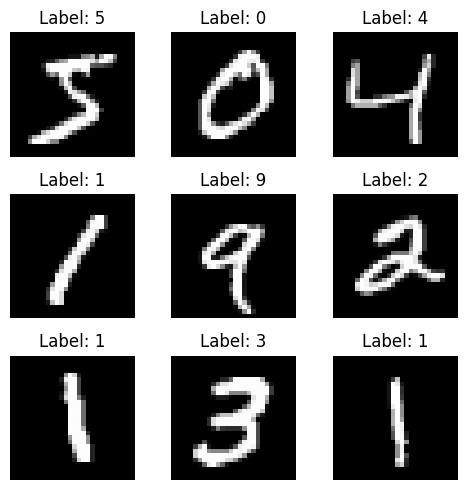

Raw image shape: (1, 28, 28)
Raw image pixel range: [0.0000, 1.0000]


In [2]:
# Load raw MNIST (original 28x28, unmodified) purely to inspect the source data
raw_transform = transforms.ToTensor()
raw_train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=raw_transform)

# Display a 3x3 grid of sample images
fig, axes = plt.subplots(3, 3, figsize=(5, 5))
for idx, ax in enumerate(axes.flat):
    img, label = raw_train_dataset[idx]
    ax.imshow(img.squeeze(0), cmap='gray')
    ax.set_title(f"Label: {label}")
    ax.axis('off')
plt.tight_layout()
plt.show()

# Print shape and pixel range of a raw image
sample_img, sample_label = raw_train_dataset[0]
print(f"Raw image shape: {tuple(sample_img.shape)}")
print(f"Raw image pixel range: [{sample_img.min().item():.4f}, {sample_img.max().item():.4f}]")

## 2. Preprocessing [4 Marks]
- Resize to 16x16
- Quantize into K = 4 levels: scale [0,1] by 3, round, cast to `torch.long`

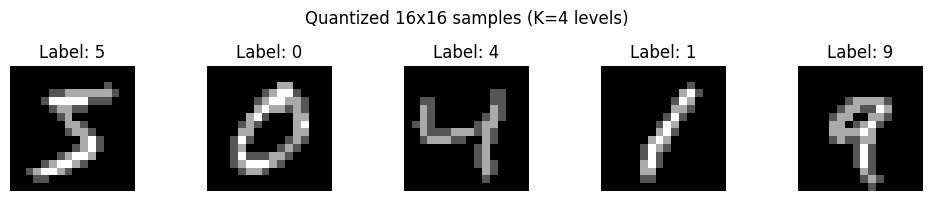

Quantized image shape: (1, 16, 16)
Quantized image dtype: torch.int64
Quantized image unique values: [0, 1, 2, 3]


In [3]:
K = 4                 # number of quantization levels (pixel values will be in {0, 1, 2, 3})
SOS_TOKEN = K         # reserved Start-of-Sequence token (value 4) used later for PixelRNN

def quantize(x):
    """Scale a [0,1] tensor by (K-1)=3, round to nearest integer, cast to torch.long."""
    return torch.round(x * (K - 1)).long()

transform = transforms.Compose([
    transforms.Resize((16, 16)),
    transforms.ToTensor(),
    transforms.Lambda(quantize),
])

# Quick dataset (same transform we will use everywhere) just to sanity-check quantization
_check_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)

fig, axes = plt.subplots(1, 5, figsize=(10, 2))
for idx, ax in enumerate(axes.flat):
    img, label = _check_dataset[idx]
    ax.imshow(img.squeeze(0).float() / (K - 1), cmap='gray', vmin=0, vmax=1)
    ax.set_title(f"Label: {label}")
    ax.axis('off')
plt.suptitle("Quantized 16x16 samples (K=4 levels)")
plt.tight_layout()
plt.show()

sample_q, _ = _check_dataset[0]
print(f"Quantized image shape: {tuple(sample_q.shape)}")
print(f"Quantized image dtype: {sample_q.dtype}")
print(f"Quantized image unique values: {torch.unique(sample_q).tolist()}")

## 3. Data Preparation [4 Marks]
- Using the **entire** MNIST dataset (no sub-sampling) — 60,000 train / 10,000 test — with a 90/10 train/val split, seed = 42
- DataLoaders, batch size = 64

*(Note: the assignment spec asks for an 8,000/1,000 sub-sample; this version uses the full dataset instead since training time isn't a constraint here. Swap back to the sub-sampled version if you need to match the graded spec exactly.)*

In [4]:
full_train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
full_test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

# Using the full dataset (no sub-sampling) — 90/10 train/val split of all 60,000 training images
n_train = int(0.9 * len(full_train_dataset))   # 54,000
n_val = len(full_train_dataset) - n_train      # 6,000
train_dataset, val_dataset = random_split(
    full_train_dataset, [n_train, n_val],
    generator=torch.Generator().manual_seed(SEED)
)
test_dataset = full_test_dataset               # all 10,000 test images

print(f"Train size: {len(train_dataset)} | Val size: {len(val_dataset)} | Test size: {len(test_dataset)}")

BATCH_SIZE = 64
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

NUM_EPOCHS = 10  # shared by both models (Section 4.3 / 5.3)

Train size: 54000 | Val size: 6000 | Test size: 10000


## 4. PixelCNN: Masked Convolutions [18 Marks]

### 4.1 Masked Convolution Layer [8 Marks]

In [5]:
class MaskedConv2d(nn.Conv2d):
    """
    2D convolution with an autoregressive raster-scan mask.

    Type A: masks the center pixel AND everything after it (used only for the first layer,
             since that layer must not see the pixel it is trying to predict).
    Type B: keeps the center pixel, masks only pixels after it (used for all later layers).
    """
    def __init__(self, mask_type, *args, **kwargs):
        super().__init__(*args, **kwargs)
        assert mask_type in ('A', 'B'), "mask_type must be 'A' or 'B'"
        self.mask_type = mask_type

        out_channels, in_channels, kH, kW = self.weight.shape
        mask = torch.ones(out_channels, in_channels, kH, kW)

        yc, xc = kH // 2, kW // 2

        # Zero out everything strictly after the center pixel, in raster-scan order
        mask[:, :, yc, xc + 1:] = 0
        mask[:, :, yc + 1:, :] = 0

        # Type A additionally zeroes the center pixel itself
        if mask_type == 'A':
            mask[:, :, yc, xc] = 0

        self.register_buffer('mask', mask)

    def forward(self, x):
        # Apply the mask to the weights before every forward pass
        self.weight.data *= self.mask
        return super().forward(x)

### 4.2 Architecture [4 Marks]

In [6]:
class PixelCNN(nn.Module):
    def __init__(self, K=4, channels=64):
        super().__init__()
        self.K = K
        self.conv_a = MaskedConv2d('A', 1, channels, kernel_size=7, padding=3)
        self.blocks = nn.ModuleList([
            MaskedConv2d('B', channels, channels, kernel_size=3, padding=1)
            for _ in range(5)
        ])
        self.out_conv = nn.Conv2d(channels, K, kernel_size=1)

    def forward(self, x):
        # x: (B, 1, H, W) long tensor with values in {0, ..., K-1}
        x = x.float() / (self.K - 1)
        x = F.relu(self.conv_a(x))
        for block in self.blocks:
            x = F.relu(block(x))
        logits = self.out_conv(x)   # (B, K, H, W), no activation on final layer
        return logits

### 4.3 Training [2 Marks]

In [7]:
pixelcnn_model = PixelCNN(K=K, channels=64).to(device)
pixelcnn_optimizer = torch.optim.Adam(pixelcnn_model.parameters(), lr=0.001)
pixelcnn_criterion = nn.CrossEntropyLoss()

def run_epoch_pixelcnn(model, loader, optimizer=None, criterion=pixelcnn_criterion):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss = 0.0
    total_samples = 0

    with torch.set_grad_enabled(is_train):
        for images, _ in loader:
            images = images.to(device)          # (B, 1, 16, 16) long
            targets = images.squeeze(1)          # (B, 16, 16) long

            logits = model(images)               # (B, K, 16, 16)
            loss = criterion(logits, targets)

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * images.size(0)
            total_samples += images.size(0)

    return total_loss / total_samples

pixelcnn_train_losses = []
pixelcnn_val_losses = []

_start_time = time.time()
for epoch in range(1, NUM_EPOCHS + 1):
    train_loss = run_epoch_pixelcnn(pixelcnn_model, train_loader, pixelcnn_optimizer)
    val_loss = run_epoch_pixelcnn(pixelcnn_model, val_loader, optimizer=None)

    pixelcnn_train_losses.append(train_loss)
    pixelcnn_val_losses.append(val_loss)

    print(f"[PixelCNN] Epoch {epoch}/{NUM_EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

pixelcnn_train_time = time.time() - _start_time
print(f"PixelCNN training wall-clock time: {pixelcnn_train_time:.2f} seconds")

[PixelCNN] Epoch 1/10 | Train Loss: 0.3231 | Val Loss: 0.2641
[PixelCNN] Epoch 2/10 | Train Loss: 0.2530 | Val Loss: 0.2484
[PixelCNN] Epoch 3/10 | Train Loss: 0.2470 | Val Loss: 0.2442
[PixelCNN] Epoch 4/10 | Train Loss: 0.2435 | Val Loss: 0.2428
[PixelCNN] Epoch 5/10 | Train Loss: 0.2410 | Val Loss: 0.2414
[PixelCNN] Epoch 6/10 | Train Loss: 0.2390 | Val Loss: 0.2408
[PixelCNN] Epoch 7/10 | Train Loss: 0.2372 | Val Loss: 0.2365
[PixelCNN] Epoch 8/10 | Train Loss: 0.2355 | Val Loss: 0.2347
[PixelCNN] Epoch 9/10 | Train Loss: 0.2341 | Val Loss: 0.2340
[PixelCNN] Epoch 10/10 | Train Loss: 0.2325 | Val Loss: 0.2320
PixelCNN training wall-clock time: 165.51 seconds


### 4.4 Loss Curves [1 Mark]

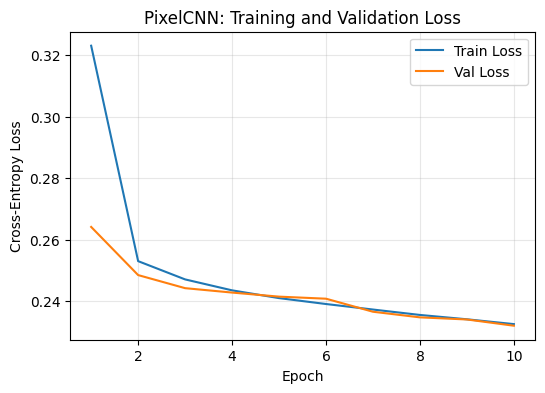

In [8]:
plt.figure(figsize=(6, 4))
plt.plot(range(1, NUM_EPOCHS + 1), pixelcnn_train_losses, label='Train Loss')
plt.plot(range(1, NUM_EPOCHS + 1), pixelcnn_val_losses, label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Cross-Entropy Loss')
plt.title('PixelCNN: Training and Validation Loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### 4.5 Test Evaluation [1 Mark]
- Report test loss (average per-pixel NLL, nats) and **bits-per-dimension (BPD)** instead of per-pixel accuracy.

*(Note: the assignment spec asks for per-pixel accuracy here; BPD is used instead since it's the standard likelihood-based metric for autoregressive image models — `BPD = test_loss / ln(2)`.)*

In [9]:
def evaluate_pixelcnn(model, loader, criterion=pixelcnn_criterion):
    model.eval()
    total_loss = 0.0
    total_samples = 0

    with torch.no_grad():
        for images, _ in loader:
            images = images.to(device)
            targets = images.squeeze(1)

            logits = model(images)
            loss = criterion(logits, targets)

            total_loss += loss.item() * images.size(0)
            total_samples += images.size(0)

    avg_loss = total_loss / total_samples
    bpd = avg_loss / math.log(2)   # convert nats/pixel (NLL) to bits/dimension
    return avg_loss, bpd

pixelcnn_test_loss, pixelcnn_test_bpd = evaluate_pixelcnn(pixelcnn_model, test_loader)
print(f"PixelCNN Test Loss (NLL, nats/pixel): {pixelcnn_test_loss:.4f}")
print(f"PixelCNN Test BPD (bits/dimension): {pixelcnn_test_bpd:.4f}")

PixelCNN Test Loss (NLL, nats/pixel): 0.2309
PixelCNN Test BPD (bits/dimension): 0.3331


### 4.6 Autoregressive Generation [2 Marks]

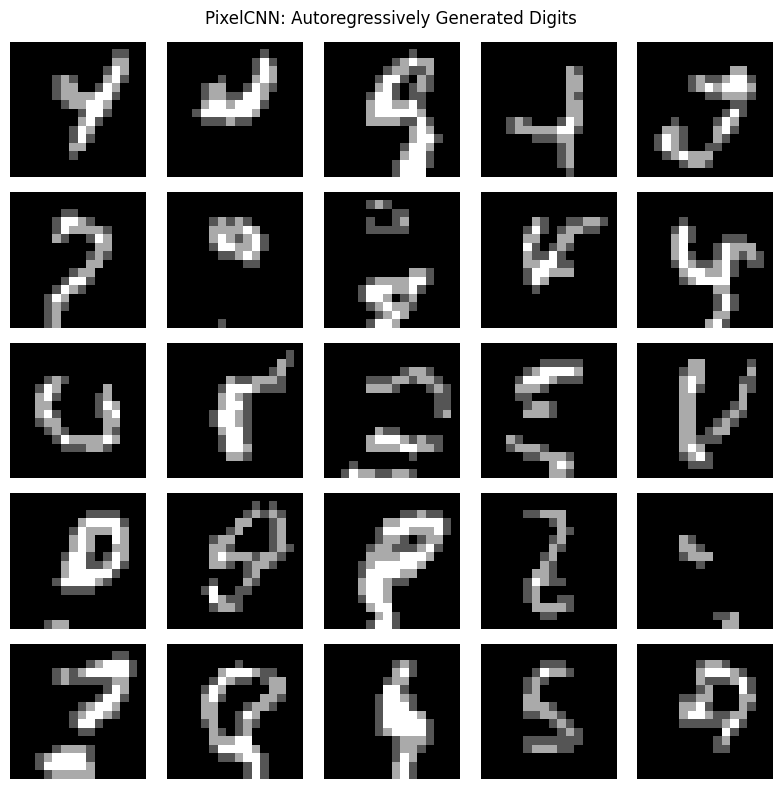

In [10]:
def generate_pixelcnn(model, n_samples=25, img_size=16, K=4, seed=42):
    model.eval()
    torch.manual_seed(seed)
    canvas = torch.zeros(n_samples, 1, img_size, img_size, dtype=torch.long, device=device)

    with torch.no_grad():
        for i in range(img_size):
            for j in range(img_size):
                logits = model(canvas)                          # (n, K, H, W)
                probs = F.softmax(logits[:, :, i, j], dim=1)     # (n, K)
                pixel = torch.multinomial(probs, num_samples=1).squeeze(1)  # (n,)
                canvas[:, 0, i, j] = pixel

    return canvas.cpu()

pixelcnn_generated = generate_pixelcnn(pixelcnn_model, n_samples=25, img_size=16, K=K, seed=42)

fig, axes = plt.subplots(5, 5, figsize=(8, 8))
for idx, ax in enumerate(axes.flat):
    img = pixelcnn_generated[idx, 0].float() / (K - 1)
    ax.imshow(img, cmap='gray', vmin=0, vmax=1)
    ax.axis('off')
plt.suptitle("PixelCNN: Autoregressively Generated Digits")
plt.tight_layout()
plt.show()

## 5. PixelRNN: Sequential LSTM [19 Marks]

### 5.1 Shifted Input [3 Marks]

In [11]:
def make_shifted_input(x_flat, sos_token=SOS_TOKEN):
    """
    x_flat: (B, L) long tensor of true pixel values (raster-scan flattened image).
    Returns the causally-shifted input where position t's input is the true pixel
    value at position t-1, with a dedicated SOS token (value 4) at position 0.
    """
    batch_size = x_flat.size(0)
    sos_column = torch.full((batch_size, 1), sos_token, dtype=torch.long, device=x_flat.device)
    shifted_input = torch.cat([sos_column, x_flat[:, :-1]], dim=1)
    return shifted_input

### 5.2 Architecture [6 Marks]

In [12]:
class PixelRNN(nn.Module):
    def __init__(self, K=4, embed_dim=16, hidden_dim=64):
        super().__init__()
        self.embedding = nn.Embedding(K + 1, embed_dim)   # K pixel values + 1 SOS token
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, K)

    def forward(self, x, hidden=None):
        # x: (B, L) long tensor of token ids
        emb = self.embedding(x)                # (B, L, embed_dim)
        out, hidden = self.lstm(emb, hidden)    # (B, L, hidden_dim)
        logits = self.fc(out)                   # (B, L, K)
        return logits, hidden

### 5.3 Training [2 Marks]

In [13]:
pixelrnn_model = PixelRNN(K=K, embed_dim=16, hidden_dim=64).to(device)
pixelrnn_optimizer = torch.optim.Adam(pixelrnn_model.parameters(), lr=0.001)
pixelrnn_criterion = nn.CrossEntropyLoss()

def run_epoch_pixelrnn(model, loader, optimizer=None, criterion=pixelrnn_criterion):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss = 0.0
    total_samples = 0

    with torch.set_grad_enabled(is_train):
        for images, _ in loader:
            images = images.to(device).squeeze(1)          # (B, 16, 16) long
            x_flat = images.reshape(images.size(0), -1)     # (B, 256)

            inp = make_shifted_input(x_flat, sos_token=SOS_TOKEN)  # (B, 256)
            target = x_flat                                        # (B, 256)

            logits, _ = model(inp)                          # (B, 256, K)
            loss = criterion(logits.permute(0, 2, 1), target)  # (B, K, 256) vs (B, 256)

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * images.size(0)
            total_samples += images.size(0)

    return total_loss / total_samples

pixelrnn_train_losses = []
pixelrnn_val_losses = []

_start_time = time.time()
for epoch in range(1, NUM_EPOCHS + 1):
    train_loss = run_epoch_pixelrnn(pixelrnn_model, train_loader, pixelrnn_optimizer)
    val_loss = run_epoch_pixelrnn(pixelrnn_model, val_loader, optimizer=None)

    pixelrnn_train_losses.append(train_loss)
    pixelrnn_val_losses.append(val_loss)

    print(f"[PixelRNN] Epoch {epoch}/{NUM_EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

pixelrnn_train_time = time.time() - _start_time
print(f"PixelRNN training wall-clock time: {pixelrnn_train_time:.2f} seconds")

[PixelRNN] Epoch 1/10 | Train Loss: 0.3982 | Val Loss: 0.3165
[PixelRNN] Epoch 2/10 | Train Loss: 0.2941 | Val Loss: 0.2792
[PixelRNN] Epoch 3/10 | Train Loss: 0.2727 | Val Loss: 0.2639
[PixelRNN] Epoch 4/10 | Train Loss: 0.2587 | Val Loss: 0.2541
[PixelRNN] Epoch 5/10 | Train Loss: 0.2509 | Val Loss: 0.2478
[PixelRNN] Epoch 6/10 | Train Loss: 0.2459 | Val Loss: 0.2441
[PixelRNN] Epoch 7/10 | Train Loss: 0.2426 | Val Loss: 0.2418
[PixelRNN] Epoch 8/10 | Train Loss: 0.2399 | Val Loss: 0.2380
[PixelRNN] Epoch 9/10 | Train Loss: 0.2376 | Val Loss: 0.2367
[PixelRNN] Epoch 10/10 | Train Loss: 0.2358 | Val Loss: 0.2359
PixelRNN training wall-clock time: 182.59 seconds


### 5.4 Loss Curves [1 Mark]

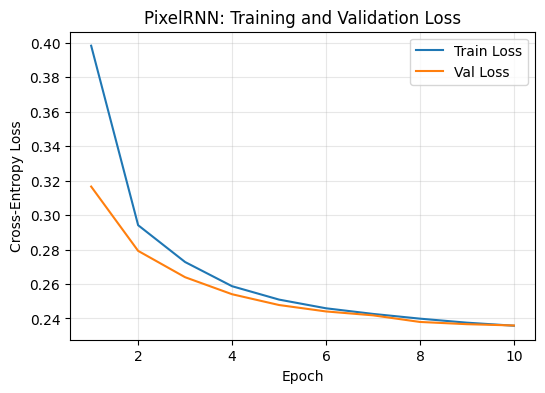

In [14]:
plt.figure(figsize=(6, 4))
plt.plot(range(1, NUM_EPOCHS + 1), pixelrnn_train_losses, label='Train Loss')
plt.plot(range(1, NUM_EPOCHS + 1), pixelrnn_val_losses, label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Cross-Entropy Loss')
plt.title('PixelRNN: Training and Validation Loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### 5.5 Test Evaluation [2 Marks]
- Report test loss and **bits-per-dimension (BPD)** instead of per-pixel accuracy.

*(Note: the assignment spec asks for per-pixel accuracy here; BPD is used instead, same definition as Section 4.5.)*

In [15]:
def evaluate_pixelrnn(model, loader, criterion=pixelrnn_criterion):
    model.eval()
    total_loss = 0.0
    total_samples = 0

    with torch.no_grad():
        for images, _ in loader:
            images = images.to(device).squeeze(1)
            x_flat = images.reshape(images.size(0), -1)

            inp = make_shifted_input(x_flat, sos_token=SOS_TOKEN)
            target = x_flat

            logits, _ = model(inp)
            loss = criterion(logits.permute(0, 2, 1), target)

            total_loss += loss.item() * images.size(0)
            total_samples += images.size(0)

    avg_loss = total_loss / total_samples
    bpd = avg_loss / math.log(2)   # convert nats/pixel (NLL) to bits/dimension
    return avg_loss, bpd

pixelrnn_test_loss, pixelrnn_test_bpd = evaluate_pixelrnn(pixelrnn_model, test_loader)
print(f"PixelRNN Test Loss (NLL, nats/pixel): {pixelrnn_test_loss:.4f}")
print(f"PixelRNN Test BPD (bits/dimension): {pixelrnn_test_bpd:.4f}")

PixelRNN Test Loss (NLL, nats/pixel): 0.2347
PixelRNN Test BPD (bits/dimension): 0.3386


### 5.6 Autoregressive Generation [5 Marks]

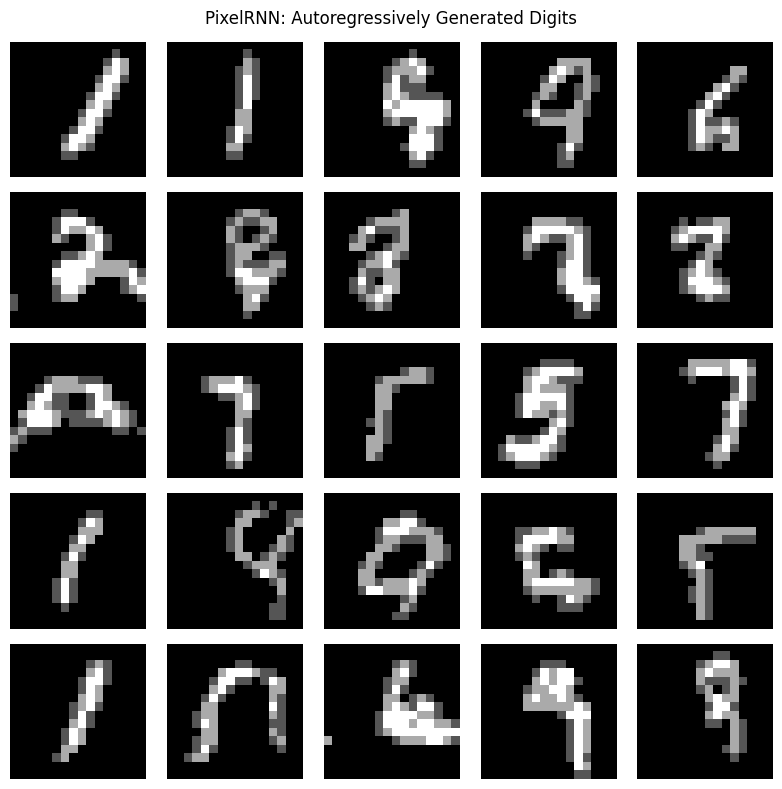

In [16]:
def generate_pixelrnn(model, n_samples=25, seq_len=256, sos_token=SOS_TOKEN, seed=42):
    model.eval()
    torch.manual_seed(seed)

    generated = torch.zeros(n_samples, seq_len, dtype=torch.long, device=device)
    input_token = torch.full((n_samples, 1), sos_token, dtype=torch.long, device=device)
    hidden = None

    with torch.no_grad():
        for t in range(seq_len):
            logits, hidden = model(input_token, hidden)     # logits: (n, 1, K)
            probs = F.softmax(logits[:, -1, :], dim=1)       # (n, K)
            pixel = torch.multinomial(probs, num_samples=1).squeeze(1)  # (n,)
            generated[:, t] = pixel
            input_token = pixel.unsqueeze(1)                 # feed sampled pixel back in

    return generated.cpu()

pixelrnn_generated = generate_pixelrnn(pixelrnn_model, n_samples=25, seq_len=16 * 16,
                                        sos_token=SOS_TOKEN, seed=42)
pixelrnn_generated_images = pixelrnn_generated.view(25, 16, 16)

fig, axes = plt.subplots(5, 5, figsize=(8, 8))
for idx, ax in enumerate(axes.flat):
    img = pixelrnn_generated_images[idx].float() / (K - 1)
    ax.imshow(img, cmap='gray', vmin=0, vmax=1)
    ax.axis('off')
plt.suptitle("PixelRNN: Autoregressively Generated Digits")
plt.tight_layout()
plt.show()

## 6. Comparing the Two Models [3 Marks]
- Tabulate **bits-per-dimension (BPD)** and training wall-clock time for both models (BPD replaces per-pixel accuracy).

In [17]:
comparison_df = pd.DataFrame({
    'Model': ['PixelCNN', 'PixelRNN'],
    'Test BPD (bits/dim)': [pixelcnn_test_bpd, pixelrnn_test_bpd],
    'Training Wall-Clock Time (s)': [pixelcnn_train_time, pixelrnn_train_time],
})
comparison_df

,Model,Test BPD (bits/dim),Training Wall-Clock Time (s)
0,PixelCNN,0.333089,165.512353
1,PixelRNN,0.338623,182.590506
